In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [2]:
# Load the wine dataset
wine = load_wine()
X = wine.data

# Calculate the NRMSE that is used in the paper
def get_nrmse(true_data, imputed_data, mask):
    mse = np.mean((true_data[mask] - imputed_data[mask]) ** 2)
    var = np.var(true_data[mask])
    return np.sqrt(mse / var)

np.random.seed(42)

In [3]:
# The MCAR at three different rates used in the paper: 10%, 20%, and 30%
for rate in [0.10, 0.20, 0.30]:
    # MCAR
    mask = np.random.rand(*X.shape) < rate
    X_miss = X.copy()
    X_miss[mask] = np.nan

    # Main missForest algorhithm
    imputer = IterativeImputer(
        estimator=RandomForestRegressor(n_estimators=100, random_state=42),
        max_iter=10,
        initial_strategy="mean",
        imputation_order="ascending",
        random_state=42
    )
    
    X_imputed = imputer.fit_transform(X_miss)
    
    score = get_nrmse(X, X_imputed, mask)
    print(f"Missing {int(rate*100)}%: NRMSE = {round(score, 4)}")

C:\Users\paulv\anaconda3\Lib\site-packages\sklearn\impute\_iterative.py:801: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


Missing 10%: NRMSE = 0.2384


C:\Users\paulv\anaconda3\Lib\site-packages\sklearn\impute\_iterative.py:801: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


Missing 20%: NRMSE = 0.2386
Missing 30%: NRMSE = 0.2663


C:\Users\paulv\anaconda3\Lib\site-packages\sklearn\impute\_iterative.py:801: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


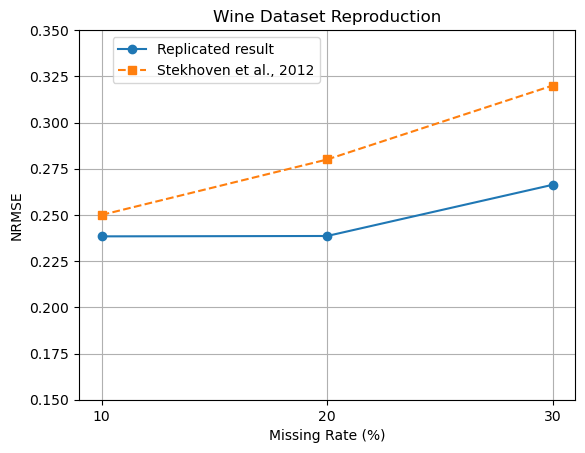

In [4]:
# Graph of the results
rates = [10, 20, 30]
replicated_nrmse = [0.2384, 0.2386, 0.2663]
paper_nrmse = [0.25, 0.28, 0.32]

plt.plot(rates, replicated_nrmse, marker='o', label='Replicated result')
plt.plot(rates, paper_nrmse, marker='s', linestyle='--', label='Stekhoven et al., 2012')
plt.xlabel('Missing Rate (%)')
plt.ylabel('NRMSE')
plt.title('Wine Dataset Reproduction')
plt.xticks([10, 20, 30])
plt.ylim(0.15, 0.35)
plt.grid(True)
plt.legend(bbox_to_anchor=[0.5, 1])
plt.show()